# 03 · Dataset: features, targets, windows, teacher grid

**Input:** `data/3_sensors/` (simulated ESP32 hours) and `data/2_clean/` (ERA5 weather, true PM).

**Output:** `data/4_features/`
| file | what | used by |
|---|---|---|
| `grid_u0.npz`, `grid_u1.npz`, `grid_u2.npz` | 23 features of **all** stations for every hour (one file per virtual unit) + weather + true PM | teacher (04) and student (05) |
| `windows_A.parquet` | which (station, hour) can be a Model A training example | 04, 05 |
| `windows_B.parquet` | same for Model B (SPS30 broken) + its 5 "last good PM" inputs | 05 |
| `kd_windows.parquet` | the windows the teacher must make outputs for (distillation) | 04, 05 |

| | student (on the ESP32) | teacher (cloud) |
|---|---|---|
| sees | 24 h of **one** station: 23 features | 24 h of **all** stations: the same 23 features + 7 ERA5 weather values |
| predicts | true PM change, +1 … +3 h | true PM change, +1 … +6 h |

**Rule:** inputs come only from simulated sensors. True CPCB PM is only the answer (target).

In [1]:
# imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# folders
DATA = Path("../data")
SENSORS, CLEAN = DATA / "3_sensors", DATA / "2_clean"
OUT = DATA / "4_features"
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# stations that were simulated, and the 5 stations we never train on (to test at a new place)
stations = sorted({p.stem.rsplit("_u", 1)[0] for p in SENSORS.glob("*_u*.parquet")})
HOLDOUT = ["patparganj_delhi_dpcc", "rohini_delhi_dpcc", "sector_125_noida_uppcb", "sirifort_delhi_cpcb", "sonia_vihar_delhi_dpcc"]
print(len(stations), "stations, hold-out:", HOLDOUT)

32 stations, hold-out: ['patparganj_delhi_dpcc', 'rohini_delhi_dpcc', 'sector_125_noida_uppcb', 'sirifort_delhi_cpcb', 'sonia_vihar_delhi_dpcc']


## 1. The 23 features (what the ESP32 computes every hour)

| # | feature | formula | why |
|---|---|---|---|
| 1-3 | ln_pm25, ln_pm10, ln_pm1 | $\ln(1 + PM_{corr})$ | PM is skewed; logs make it smoother |
| 4 | coarse_ratio | $(PM_{10}-PM_{2.5})/\max(PM_1,1)$, clipped 0-10 | dust indicator |
| 5-9 | t, rh, p, wind_u, wind_v | as measured ($p - 1000$) | weather drives dispersion |
| 10 | rain_frac | wet fraction of the hour | rain washes PM out |
| 11 | ln_lux | $\ln(1 + lux)$ | sunshine / mixing layer / smog |
| 12-13 | mq7_n, mq135_n | $\ln(R_s / R_{base})$ | gas level relative to clean air |
| 14-15 | voc_n, nox_n | $(\text{ticks} - \text{base})/1000$ | same for SGP41 |
| 16-21 | hod, dow, doy as sin/cos | $\sin(2\pi x/P), \cos(2\pi x/P)$ | daily / weekly / yearly cycles |
| 22 | aqi_now | $AQI/500$ | current AQI |
| 23 | pm_mask | 1 if the SPS30 measured this hour | tells the model when PM is missing |

Every feature also gets a **mask** (1 = real measured value, 0 = missing or filled).
Gaps of ≤ 2 hours are filled with a straight line (mask stays 0).

In [4]:
# the feature names, in the order the models see them
FEATURES = ["ln_pm25", "ln_pm10", "ln_pm1", "coarse_ratio", "t", "rh", "p", "wind_u", "wind_v", "rain_frac",
            "ln_lux", "mq7_n", "mq135_n", "voc_n", "nox_n", "hod_sin", "hod_cos", "dow_sin", "dow_cos",
            "doy_sin", "doy_cos", "aqi_now", "pm_mask"]
PM_FEATURES = ["ln_pm25", "ln_pm10", "ln_pm1", "coarse_ratio", "aqi_now", "pm_mask"]   # Model B cannot use these

In [5]:
# compute the 23 features + masks from one unit's hourly record
def make_features(rec):
    pm_ok = rec.pm_measured.to_numpy(bool)
    ist = rec.ts.dt.tz_convert("Asia/Kolkata")
    f = pd.DataFrame({
        "ln_pm25": np.log1p(rec.pm25_corr.clip(lower=0)),
        "ln_pm10": np.log1p(rec.pm10_corr.clip(lower=0)),
        "ln_pm1": np.log1p(rec.pm1.clip(lower=0)),
        "coarse_ratio": rec.coarse_ratio.clip(0, 10),
        "t": rec.t, "rh": rec.rh, "p": rec.p - 1000, "wind_u": rec.wind_u, "wind_v": rec.wind_v,
        "rain_frac": rec.rain_frac,
        "ln_lux": np.log1p(rec.lux.clip(lower=0)),
        "mq7_n": np.log(rec.mq7_rs / rec.Rbase7),
        "mq135_n": np.log(rec.mq135_rs / rec.Rbase135),
        "voc_n": (rec.sraw_voc - rec.base_voc) / 1000,
        "nox_n": (rec.sraw_nox - rec.base_nox) / 1000,
        "hod_sin": np.sin(2 * np.pi * ist.dt.hour / 24), "hod_cos": np.cos(2 * np.pi * ist.dt.hour / 24),
        "dow_sin": np.sin(2 * np.pi * ist.dt.dayofweek / 7), "dow_cos": np.cos(2 * np.pi * ist.dt.dayofweek / 7),
        "doy_sin": np.sin(2 * np.pi * ist.dt.dayofyear / 365), "doy_cos": np.cos(2 * np.pi * ist.dt.dayofyear / 365),
        "aqi_now": rec.aqi_pm / 500,
        "pm_mask": pm_ok.astype(float),
    }).replace([np.inf, -np.inf], np.nan)
    mask = f.notna().astype(np.uint8)
    for col in PM_FEATURES[:-1]:              # PM features are only "real" when the SPS30 measured
        mask[col] = mask[col] * pm_ok
    return f, mask

In [6]:
# fill gaps of at most 2 hours with a straight line (longer gaps stay empty)
def fill_short_gaps(f):
    filled = f.copy()
    for col in f.columns:
        s = f[col]
        gap_length = s.isna().groupby(s.notna().cumsum()).transform("sum")
        line = s.interpolate(limit_area="inside")
        filled[col] = np.where(s.isna() & (gap_length <= 2), line, s)
    return filled

## 2. Targets
For hour $t$ and horizon $h$: $\;y_h = \ln(1 + PM_{true}[t+h]) - \ln(1 + PM_{true}[t])$

The model predicts the **change** of the true PM. Order: `[pm25_h1, pm25_h2, pm25_h3, pm10_h1, pm10_h2, pm10_h3]`.

In [7]:
# targets for every hour: change of the true PM after h hours
def targets(true_pm25, true_pm10, horizons=3):
    n = len(true_pm25)
    y = np.full((n, 2 * horizons), np.nan, np.float32)
    for k, pm in enumerate((true_pm25, true_pm10)):
        log_pm = np.log1p(np.asarray(pm, float))
        for h in range(1, horizons + 1):
            y[: n - h, k * horizons + h - 1] = log_pm[h:] - log_pm[: n - h]
    return y

## 3. Splits by time
| split | years | why |
|---|---|---|
| train | 2018-2023 | learn |
| val | 2024 | choose when to stop training |
| test | 2025 - Sep 2026 | final score, never touched before |

In [8]:
# which split an hour belongs to (by IST year)
def split_of(ts):
    year = ts.dt.tz_convert("Asia/Kolkata").dt.year
    return np.select([year <= 2023, year == 2024], ["train", "val"], "test")

## 4. Build the feature table of every unit

In [9]:
# one unit: record -> features + masks + the columns the windows need
def build_unit(path):
    rec = pd.read_parquet(path)
    f, mask = make_features(rec)
    f = fill_short_gaps(f)
    table = pd.concat([rec[["ts"]], f, mask.add_prefix("m_")], axis=1)
    for col in ("true_pm25", "true_pm10", "pm25_corr", "pm10_corr", "aqi_pm", "pm_measured", "pm_state"):
        table[col] = rec[col]
    table["split"] = split_of(rec.ts)
    float_cols = table.select_dtypes("float64").columns
    table[float_cols] = table[float_cols].astype(np.float32)
    return table

In [10]:
# build all unit tables (skips existing ones)
for path in sorted(SENSORS.glob("*_u*.parquet")):
    out_file = OUT / path.name
    if not out_file.exists():
        build_unit(path).to_parquet(out_file, index=False)
print(len(list(OUT.glob("*_u*.parquet"))), "unit feature tables")

96 unit feature tables


In [11]:
# all tables share the same hours, so 'row' = the same hour everywhere
hours = pd.read_parquet(OUT / f"{stations[0]}_u0.parquet", columns=["ts"]).ts
print(len(hours), "hours from", hours.iloc[0], "to", hours.iloc[-1])

76680 hours from 2017-12-31 18:30:00+00:00 to 2026-09-30 17:30:00+00:00


## 5. Student windows
**Model A** example at hour $t$: the last 24 hours are complete (after the 2-hour fill), PM was measured in ≥ 20 of them,
PM is ok now, and the 3 true targets exist.

**Model B** (SPS30 broken): take a Model A example and pretend PM was lost $k$ hours ago ($k$ = 1…24, random).
Inputs: the 17 non-PM features + 5 "last good PM" numbers. Targets are relative to the last good hour $t-k$:
$y_h = \ln(1+PM[t+h]) - \ln(1+PM[t-k])$.

In [12]:
# Model A windows of one unit table
def model_a_rows(table):
    x = table[FEATURES].to_numpy()
    complete_24h = pd.Series(np.isfinite(x).all(axis=1)).rolling(24).sum().to_numpy() == 24
    measured_24h = table.pm_measured.astype(float).rolling(24).sum().to_numpy()
    pm_ok_now = table.pm_state.isin(["ok", "filled_le_1h"]).to_numpy()
    has_targets = np.isfinite(targets(table.true_pm25, table.true_pm10)).all(axis=1)
    return np.flatnonzero(complete_24h & (measured_24h >= 20) & pm_ok_now & has_targets)

In [13]:
# Model B windows: pretend the SPS30 died k hours before row t
def model_b_rows(table, rows, rng):
    k = rng.integers(1, 25, size=len(rows))
    last = rows - k
    measured = table.pm_measured.to_numpy(bool)
    ok = (last >= 3) & measured[np.maximum(last, 0)] & measured[np.maximum(last - 3, 0)]
    rows, k, last = rows[ok], k[ok], last[ok]
    ln25, ln10 = np.log1p(table.pm25_corr.to_numpy(float)), np.log1p(table.pm10_corr.to_numpy(float))
    extras = pd.DataFrame({"last_ln_pm25": ln25[last], "last_ln_pm10": ln10[last],
                           "last_aqi": table.aqi_pm.to_numpy(float)[last] / 500,
                           "hours_lost": k / 24, "pm25_trend": ln25[last] - ln25[last - 3]})
    good = extras.notna().all(axis=1).to_numpy()
    return rows[good], k[good], extras[good].reset_index(drop=True)

In [14]:
# collect the windows of every unit
rng = np.random.default_rng(0)
win_a, win_b = [], []
for i, station in enumerate(stations):
    for unit in range(3):
        table = pd.read_parquet(OUT / f"{station}_u{unit}.parquet")
        rows = model_a_rows(table)
        split = table.split.to_numpy()
        win_a.append(pd.DataFrame({"station": i, "unit": unit, "row": rows, "split": split[rows]}))
        rows_b, k, extras = model_b_rows(table, rows, rng)
        win_b.append(pd.concat([pd.DataFrame({"station": i, "unit": unit, "row": rows_b, "k": k,
                                              "split": split[rows_b]}), extras], axis=1))
win_a = pd.concat(win_a, ignore_index=True)
win_b = pd.concat(win_b, ignore_index=True)
win_a["holdout"] = win_a.station.map(lambda i: stations[i] in HOLDOUT)
win_b["holdout"] = win_b.station.map(lambda i: stations[i] in HOLDOUT)
win_a.to_parquet(OUT / "windows_A.parquet", index=False)
win_b.to_parquet(OUT / "windows_B.parquet", index=False)

In [15]:
# how many examples per split (hold-out stations counted separately)
pd.concat([win_a.assign(model="A"), win_b.assign(model="B")]).groupby(["model", "holdout", "split"]).size().unstack()

split            test    train     val
model holdout                         
A     False    794573  2597286  497369
      True     175257   572505   93619
B     False    730932  2397584  458795
      True     160792   528811   86458

## 6. Teacher grid: all stations side by side
For every virtual unit: `X[hour, station, feature]` = the **same numbers** as the student's tables.
Plus ERA5 weather `W[hour, station, 7]` (the teacher may use it, it is cloud data) and the true PM
`pm[hour, station, 2]` (only for targets).

In [16]:
# station positions + static info (lat, lon, elevation, mounting height, sheltering, is-reference)
info = pd.read_csv(DATA / "1_download" / "stations.csv").set_index("station_id").loc[stations]
static = np.column_stack([info.lat, info.lon, info.elevation_m, np.full(len(info), 3.0),
                          np.zeros(len(info)), np.zeros(len(info))]).astype(np.float32)

In [17]:
# ERA5 weather of all stations [hours, stations, 7] (same for all units)
ERA5 = ["era5_t2m", "era5_rh2m", "era5_sp", "era5_u10", "era5_v10", "era5_precip", "era5_swrad"]
W = np.stack([pd.read_parquet(CLEAN / f"{s}.parquet", columns=ERA5).to_numpy(np.float32) for s in stations], axis=1)
W.shape

(76680, 32, 7)

In [18]:
# one grid file per unit: stack the stations' feature tables
for unit in range(3):
    path = OUT / f"grid_u{unit}.npz"
    if path.exists():
        continue
    tables = [pd.read_parquet(OUT / f"{s}_u{unit}.parquet") for s in stations]
    np.savez(path,
             X=np.stack([t[FEATURES].to_numpy(np.float32) for t in tables], axis=1),
             M=np.stack([t[["m_" + c for c in FEATURES]].to_numpy(np.uint8) for t in tables], axis=1),
             pm=np.stack([t[["true_pm25", "true_pm10"]].to_numpy(np.float32) for t in tables], axis=1),
             W=W, static=static, stations=np.array(stations), holdout=np.isin(stations, HOLDOUT),
             split=split_of(hours).astype(str), ist_hour=hours.dt.tz_convert("Asia/Kolkata").dt.hour.to_numpy(),
             ts=((hours - pd.Timestamp(0, tz="UTC")) // pd.Timedelta("1s")).to_numpy())
    print("unit", unit, "saved")

unit 0 saved


unit 1 saved


unit 2 saved


In [19]:
# fairness check: the teacher grid holds exactly the student's input numbers
X = np.load(OUT / "grid_u1.npz")["X"]
checks = win_a[win_a.unit == 1].sample(20, random_state=0)
for w in checks.itertuples():
    table_x = pd.read_parquet(OUT / f"{stations[w.station]}_u1.parquet", columns=FEATURES).to_numpy(np.float32)
    assert np.array_equal(table_x[w.row - 23: w.row + 1], X[w.row - 23: w.row + 1, w.station], equal_nan=True)
print(f"student input == teacher input for all {len(checks)} checked windows")

student input == teacher input for all 20 checked windows


## 7. Windows for distillation
The teacher writes its outputs (forecast + internal states) only for a fixed sample of windows:
200 000 training + 40 000 validation windows of the 27 training stations. All student variants train on
exactly these windows, so the comparison is fair.

In [20]:
# fixed random sample of training / validation windows (training stations only)
train_pool = win_a[(win_a.split == "train") & ~win_a.holdout]
val_pool = win_a[(win_a.split == "val") & ~win_a.holdout]
kd = pd.concat([train_pool.sample(min(200_000, len(train_pool)), random_state=0),
                val_pool.sample(min(40_000, len(val_pool)), random_state=0)])
kd = kd.sort_values(["unit", "row", "station"]).reset_index(drop=True)
kd["window_id"] = np.arange(len(kd))
kd.to_parquet(OUT / "kd_windows.parquet", index=False)
kd.split.value_counts()

split
train    200000
val       40000
Name: count, dtype: int64

## 8. Look at one example

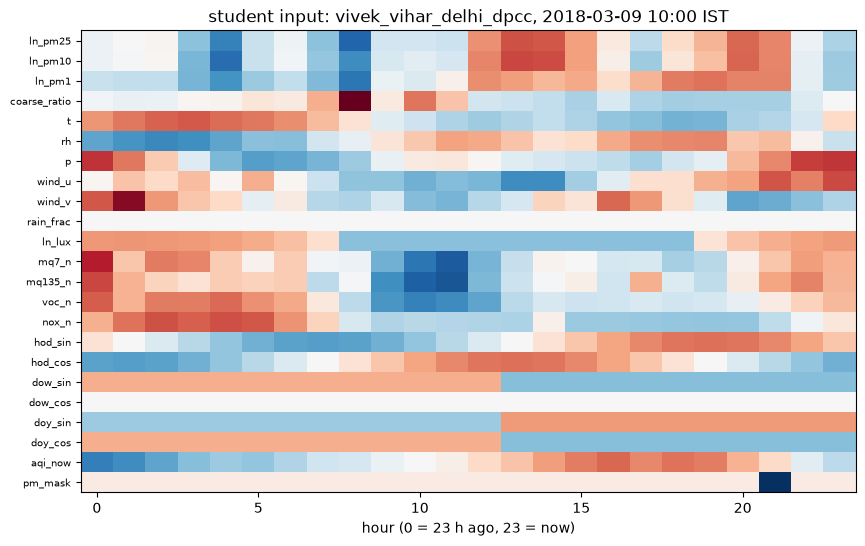

In [21]:
# one student window (24 h x 23 features), each feature scaled to its own range for display
w = kd.iloc[1000]
x = pd.DataFrame(X[w.row - 23: w.row + 1, w.station], columns=FEATURES)
plt.figure(figsize=(10, 6))
plt.imshow(((x - x.mean()) / (x.std() + 1e-6)).T, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
plt.yticks(range(len(FEATURES)), FEATURES, fontsize=7)
plt.xlabel("hour (0 = 23 h ago, 23 = now)")
plt.title(f"student input: {stations[w.station]}, {hours.iloc[w.row].tz_convert('Asia/Kolkata'):%Y-%m-%d %H:%M} IST")
plt.show()

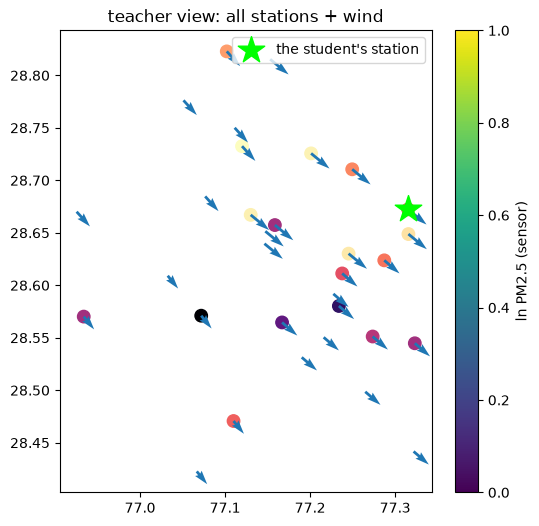

In [22]:
# what the teacher sees at the same hour: every station, its PM now (colour) and the wind (arrows)
plt.figure(figsize=(6, 6))
plt.scatter(static[:, 1], static[:, 0], c=X[w.row, :, 0], cmap="magma_r", s=80)
plt.quiver(static[:, 1], static[:, 0], W[w.row, :, 3], W[w.row, :, 4], color="tab:blue")
plt.scatter(static[w.station, 1], static[w.station, 0], marker="*", s=400, c="lime", label="the student's station")
plt.colorbar(label="ln PM2.5 (sensor)")
plt.legend()
plt.title("teacher view: all stations + wind")
plt.show()